# Synthetic Peru: a seeded reconstruction of the OISST case

A field generated in about a second with the grid, coast, seasonal cycle, trend and anomaly statistics of the OISST case off Peru, 1991–2025. It is statistically similar to that case, not a copy of any observation, so every stage can be run in under a minute and the figures illustrate the API, not the climate. The real OISST, OSTIA, ERA5 and GLORYS cases live in the separate `xhw-benchmark` project.

Read [the tutorial guide](../docs/TUTORIALS.md). Saved outputs can be read without data; re-execution needs the optional `examples/requirements.txt`. No download is triggered by this notebook.

## Configuration of these saved outputs

| Choice | Value |
|---|---|
| Publication | 0.0.1 |
| Source | synthetic:peru-reconstruction-seed7 |
| Reference period | 1991-01-01 through 2020-12-31 |
| Baseline / fit mode | fixed_climatology / retrospective |
| Seasonal pooling / smoothing (days) | 11 / 31 |
| Percentile estimator | hyndman_fan_7 |
| Minimum samples | 264 |
| Leap policy | hobday_366_interp |
| Within-reference correction | none |
| Representative tail / percentile / comparator | upper / 90.0 / > |
| Minimum duration / temporal gap (days) | 5 / 2 |
| Missing / join policy | as_non_exceedance / qualify_then_join |
| Declared day | native |
| Support / spatial dimensions | surface / lat, lon |
| Domain / measure | ocean / area |
| Review status | executed; synthetic reconstruction, an illustration and not a climate result |

The MCS and detrended comparisons appear in their own cells. Tracking configuration appears in its recipe cell. Full portable specs and checksums are in `report.json` and [the saved run record](../docs/run_records/synthetic_peru.json).


In [1]:
import os
import sys
from pathlib import Path

EXAMPLES = Path.cwd() if (Path.cwd() / "_data.py").exists() else Path.cwd() / "examples"
sys.path.insert(0, str(EXAMPLES))
%matplotlib inline
output_dir = Path(os.environ.get("XHW_OUTPUT_DIR", EXAMPLES.parent / "outputs")) / "synthetic_peru"

## Named configurations for the example

`mhw` and the other names below are local Python aliases containing complete
DefinitionSpec values, not extra arguments or automatic presets in `xhw.detect`.
Inspect them with `.to_dict()`. The loader still declares the baseline, reference
period and grid. The volume example keeps its potential-temperature definition.


In [2]:
from profiles import example_profiles

definitions = example_profiles()
mhw, mcs = definitions["mhw"], definitions["mcs"]
ahw_tx90, ahw_tn90 = definitions["ahw_tx90"], definitions["ahw_tn90"]
ahw_txtn90 = definitions["ahw_txtn90"]
ahw_tx_then_tn90 = definitions["ahw_tx_then_tn90"]
{name: (spec.phenomenon, spec.profile) for name, spec in definitions.items()}


{'mhw': ('mhw', 'hobday2016'),
 'mcs': ('mcs', 'schlegel2021'),
 'ahw_tx90': ('ahw', 'perkins2013_tx90'),
 'ahw_tn90': ('ahw', 'perkins2013_tn90'),
 'ahw_txtn90': ('ahw', 'xhw_txtn90'),
 'ahw_tx_then_tn90': ('ahw', 'xhw_tx_then_tn90')}

In [3]:
from dataclasses import replace
from pathlib import Path

from _data import marine_definition, synthetic_peru_inputs
from _report import (
    lineage_catalog_status,
    spatial_summary,
    temporal_summary,
    write_report,
)
from plotting import (
    frequency_figure,
    genealogy_figure,
    largest_event,
    metrics_figure,
    sequence_figure,
    series_figure,
)

import xhw

print(f"Publication API: xHW {xhw.__version__}")

Publication API: xHW 0.0.1


## Generate the reconstruction (seed 7) and declare it like any other input

The input is generated, not read: `synthetic_peru_inputs()` returns a Dataset of daily SST on the 32 x 20 Peru grid, with explicit grid, baseline and detector specs. The generator is seeded, so every run gives the same field; its checksum identifies it.

In [4]:
raw, grid, baseline, definition = synthetic_peru_inputs()
# Alias of the complete, case-specific definition.
mhw = definition
grid.check(raw)
print("Synthetic Peru reconstruction, 1991–2025; reference 1991–2020; seed 7.")
prepared = xhw.interpolate_gaps(
    raw, variable="sst", grid=grid, max_days=2, max_filled_fraction=0.05
)

Synthetic Peru reconstruction, 1991–2025; reference 1991–2020; seed 7.


## Marine heatwaves and cold spells use distinct percentile tails

A marine heatwave is the upper tail and a marine cold spell the lower tail of the same fitted reference. Each has its own threshold and `XMask`; the catalog holds one row per event and cell.

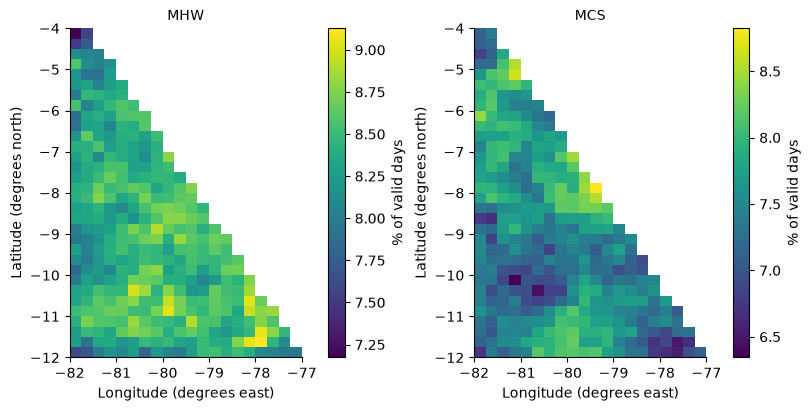

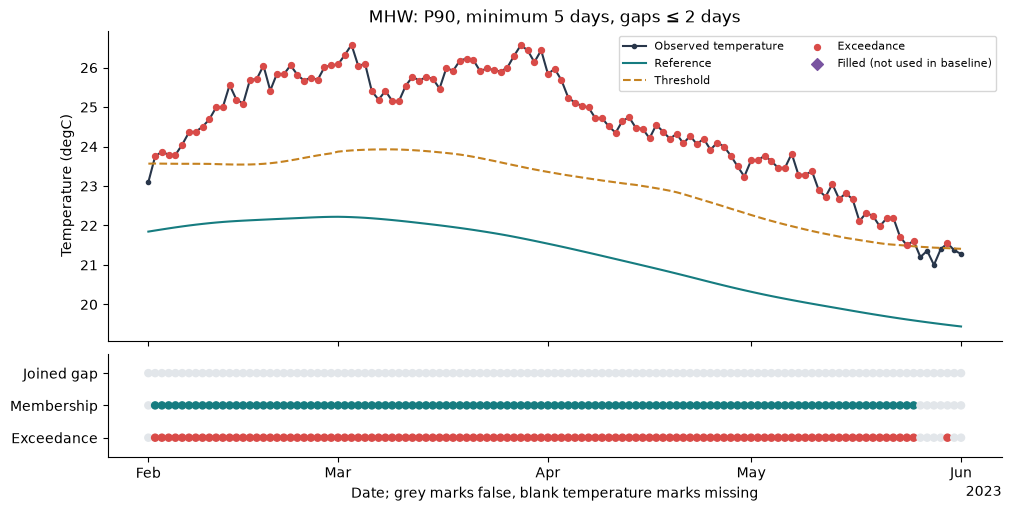

In [5]:
masks, catalogs, metrics = {}, {}, {}
for name, detector in (("MHW", definition), ("MCS", marine_definition(cold=True))):
    fitted = xhw.fit_baseline(
        prepared, variable="sst", grid=grid, baseline=baseline, definition=detector
    )
    fitted.check_invariants()
    masks[name] = xhw.detect(
        prepared, variable="sst", grid=grid, definition=detector, baseline_result=fitted
    )
    masks[name].check_invariants()
    catalogs[name] = xhw.build_catalog(masks[name], analysis_mode="retrospective")
    catalogs[name].check_against(masks[name])
    metrics[name] = temporal_summary(masks[name], catalogs[name])
mask = masks["MHW"]
figure = frequency_figure(masks, output_dir)
figure = series_figure(
    raw,
    mask,
    variable="sst",
    selection={"lat": 15, "lon": 10},
    period=("2023-02-01", "2023-06-01"),
    output_dir=output_dir,
)

## Compare the same definition with a retrospective detrended baseline

A detrended baseline answers a different reference question than the fixed 1991–2020 climatology. The Jaccard index compares event membership on jointly valid cell-days; it does not rank the methods.

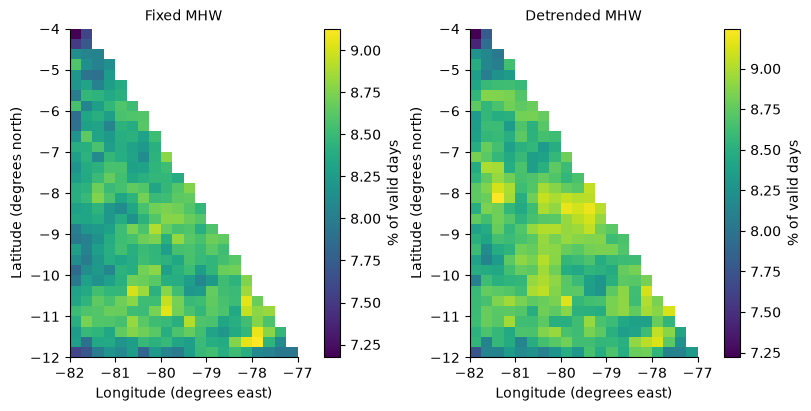

In [6]:
dynamic = replace(baseline, method="detrended")
fitted_dynamic = xhw.fit_baseline(
    prepared, variable="sst", grid=grid, baseline=dynamic, definition=mhw
)
fitted_dynamic.check_invariants()
dynamic_mask = xhw.detect(
    prepared, variable="sst", grid=grid, definition=mhw, baseline_result=fitted_dynamic
)
dynamic_mask.check_invariants()
dynamic_catalog = xhw.build_catalog(dynamic_mask, analysis_mode="retrospective")
dynamic_catalog.check_against(dynamic_mask)
metrics["detrended"] = temporal_summary(dynamic_mask, dynamic_catalog)
common_valid = mask.dataset.valid & dynamic_mask.dataset.valid
a, b = mask.dataset.event_membership, dynamic_mask.dataset.event_membership
union = int(((a | b) & common_valid).sum())
metrics["fixed_detrended_jaccard"] = (
    float(((a & b) & common_valid).sum()) / union if union else 1.0
)
figure = frequency_figure(
    {"Fixed MHW": mask, "Detrended MHW": dynamic_mask}, output_dir, name="baseline_comparison"
)

## Track event-membership patches; the default recipe would not track

The default recipe does not track. Tracking is an explicit last step that links patches sharing grid cells on consecutive days.

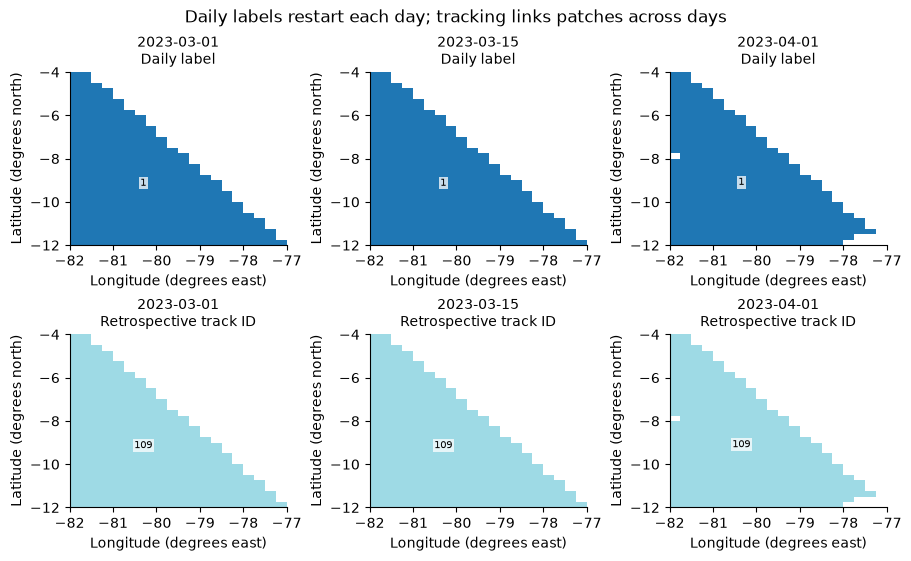

In [7]:
recipe = xhw.SpatialRecipe(
    input_layer="event_membership",
    steps=(
        xhw.RecipeStep.segment(
            footprint=xhw.Footprint.connected(1), min_area=xhw.MinArea.default()
        ),
        xhw.RecipeStep.track(min_overlap=0.0, max_gap_days=0, min_duration_days=5),
    ),
)
objects = xhw.build_objects(mask, recipe=recipe, analysis_mode="retrospective")
objects.check_invariants()
objects.check_against(mask)
figure = sequence_figure(objects, ["2023-03-01", "2023-03-15", "2023-04-01"], output_dir)

## Derive branches and spacetime events with area-weighted intensity

The lineage graph keeps every parent and child: a split ends a branch and starts new ones. Intensity is the area-weighted signed mean.

Catalog export constraint: 28 graph components are shorter than 5 days. Use graph.dataset for these components.


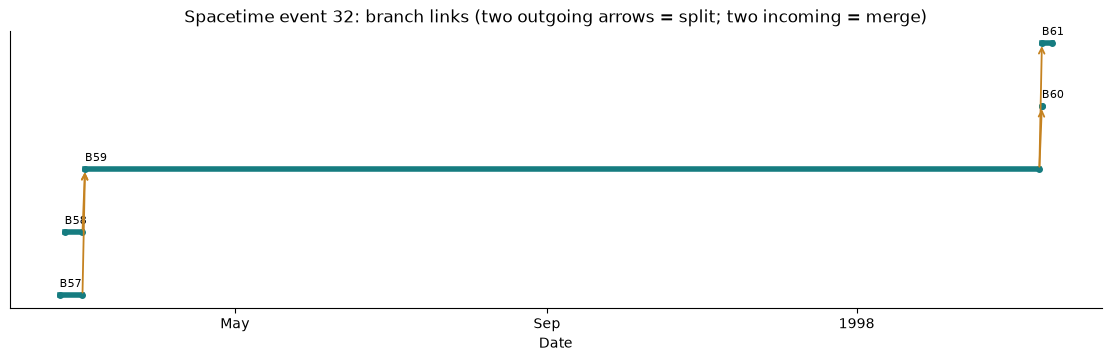

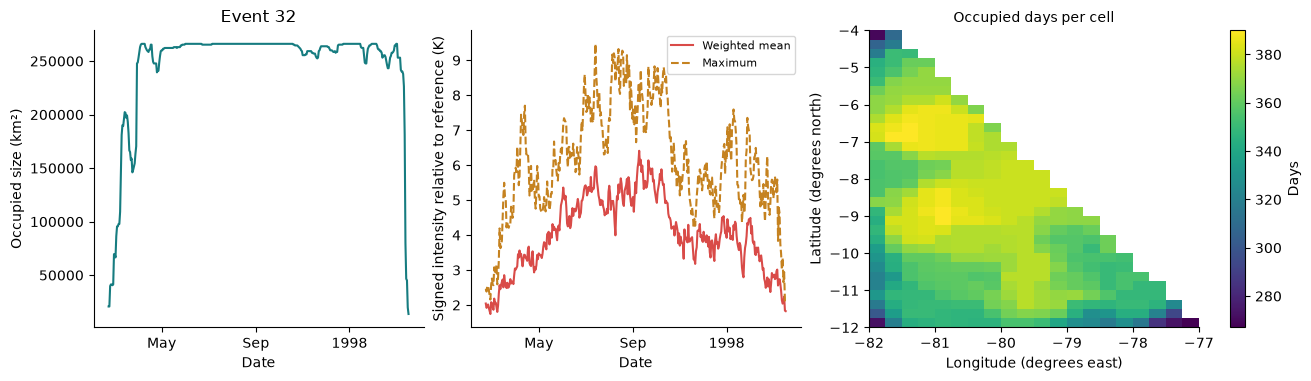

In [8]:
graph = xhw.build_lineage(objects, field=mask.intensity(), weighted=True)
graph.check_invariants()
graph.check_against(objects)
metrics["lineage_catalog_export"] = lineage_catalog_status(graph, mask)
event = largest_event(graph)
figure = genealogy_figure(graph, event, output_dir)
metrics_figure(graph, objects, event, output_dir)
del figure
metrics["spatial"] = spatial_summary(objects, graph)
metrics["largest_size_time_event"] = int(event)

## Preserve the distinction between reproduced output and scientific approval

The report holds versions, exact specs, source checksum and review state. A reproducible number is not a reviewed scientific conclusion.

In [9]:
report = write_report(
    output_dir,
    "synthetic_peru",
    metrics,
    grid=grid,
    baseline=baseline,
    definition=mhw,
    recipe=recipe,
    graph=graph,
    review="executed; synthetic reconstruction, an illustration and not a climate result",
    extra={
        "selection": "synthetic: 32 x 20 cells, 0.25 degree, lat -12 to -4, lon -82 to -77",
        "generator": "examples/_data.py::synthetic_peru, seed 7, rounded to 0.01 degC",
        "dynamic_baseline": dynamic.to_dict(),
        "comparison_denominator": "union of membership on jointly valid cell-days",
        "common_valid_cell_days": int(common_valid.sum()),
        "oisst_registered_reference": {
            "per_cell_events": 16702,
            "tracks": 118,
            "spacetime_events": 136,
            "daily_patches": 2956,
            "note": "the reconstruction is calibrated to these figures only roughly",
        },
    },
)

{
  "MHW": {
    "events": 14797,
    "exceedance_cell_days": 447315,
    "event_cell_days": 375893,
    "joined_cell_days": 2503,
    "valid_cell_days": 4461616,
    "filled_cell_days": 0,
    "max_duration_days": 391
  },
  "MCS": {
    "events": 22978,
    "exceedance_cell_days": 443673,
    "event_cell_days": 336518,
    "joined_cell_days": 4164,
    "valid_cell_days": 4461616,
    "filled_cell_days": 0,
    "max_duration_days": 119
  },
  "detrended": {
    "events": 14854,
    "exceedance_cell_days": 457652,
    "event_cell_days": 385752,
    "joined_cell_days": 2665,
    "valid_cell_days": 4461616,
    "filled_cell_days": 0,
    "max_duration_days": 390
  },
  "fixed_detrended_jaccard": 0.9193811772651442,
  "lineage_catalog_export": {
    "status": "not exportable as qualified EventCatalog",
    "short_components": 28,
    "reason": "qualified events shorter than min_duration_days"
  },
  "spatial": {
    "patches": 2623,
    "tracks": 112,
    "branches": 292,
    "spacetime_e

## Interpretation and provenance

Inspect the executed report and the [metrics guide](../docs/METRICS.md). Keep domain, grid, reference, tail, missing policy, persistence, connectivity and overlap denominator attached to these numbers. Genealogy is not attribution. Figures are produced by xarray/Matplotlib, not a native xHW graphics API.

In [10]:
{
    "review_status": report["review_status"],
    "versions": report["versions"],
    "source_checksum": report["source"]["fields"]["checksum"],
}

{'review_status': 'executed; synthetic reconstruction, an illustration and not a climate result',
 'versions': {'xhw': '0.0.1',
  'numpy': '2.5.4',
  'xarray': '2026.7.0',
  'scipy': '1.16.3',
  'matplotlib': '3.11.2',
  'h5netcdf': '1.8.1',
  'nbformat': '5.11.1',
  'nbclient': '0.11.0'},
 'source_checksum': 'sha256:f90a56e8314d810ccd3f07bb9cc4ffcb86b0429230987b255f51f1b372fecc6f'}